In [1]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no gpu")
# هذا الكود استخدمته لاني بحثت في النت شلون اعرف الكود يشتغل على CPU OR GPU لان كان مشير

True Tesla T4


In [2]:
!pip install roboflow ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 32.9 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [3]:
from ultralytics import YOLO
model = YOLO('yolo26s.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
from roboflow import Roboflow
rf = Roboflow(api_key="CFPqVUZkUzpq8L3aQPhe")
project = rf.workspace("noora-alkhalaqi").project("bahraini-currency-1ka60")
version = project.version(3)
dataset = version.download("yolo26")



loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bahraini-currency-3 in yolo26:: 100%|██████████| 1927/1927 [00:10<00:00, 179.26it/s] 


In [5]:
model.train(data='/content/bahraini-currency-3/data.yaml', epochs= 5)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bahraini-currency-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c8fa9072450>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [6]:
finetuned_model = YOLO('/content/runs/detect/train/weights/best.pt')

In [7]:
results = finetuned_model('/content/bahraini-currency-3/test/images/images-2-_jpg.rf.904e03434ffc3997df48140e61862ef1.jpg')


image 1/1 /content/bahraini-currency-3/test/images/images-2-_jpg.rf.904e03434ffc3997df48140e61862ef1.jpg: 448x640 1 0.5 BD, 12.8ms
Speed: 1.6ms preprocess, 12.8ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)


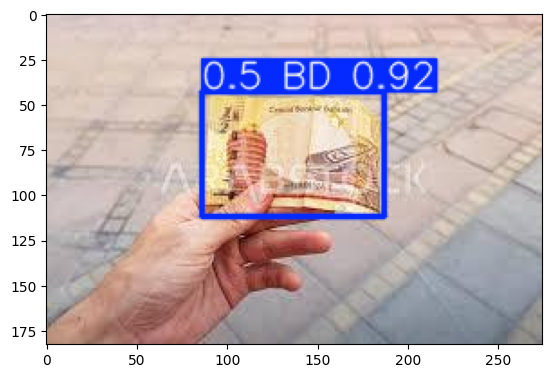

In [8]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1])



In [9]:
finetuned_model = YOLO('/content/runs/detect/train/weights/last.pt')

finetuned_model.train(data='/content/bahraini-currency-3/data.yaml', epochs= 15)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bahraini-currency-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, n

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c8c84bb0f80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [10]:
finetuned_model = YOLO('/content/runs/detect/train-3/weights/best.pt')

FileNotFoundError: [Errno 2] No such file or directory: '/content/runs/detect/train-3/weights/best.pt'

In [11]:
results = finetuned_model('/content/bahraini-currency-3/valid/images/20_0009_jpg.rf.587d93c0e83ae5c4ff4e1072f4214572.jpg')


image 1/1 /content/bahraini-currency-3/valid/images/20_0009_jpg.rf.587d93c0e83ae5c4ff4e1072f4214572.jpg: 640x320 1 20 BD, 11.6ms
Speed: 1.6ms preprocess, 11.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 320)


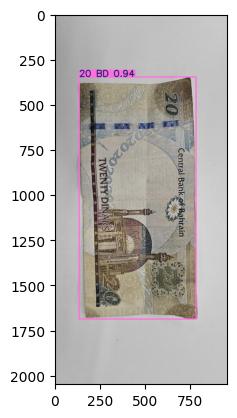

In [12]:

import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1])

In [13]:
metrics = finetuned_model.val(split="test")

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 46.8±41.1 MB/s, size: 249.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/bahraini-currency-3/test/labels... 70 images, 0 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 70/70 400.6it/s 0.2s
val: /content/bahraini-currency-3/test/images/0_5_0013_jpg.rf.7706af5d71cf6667c0ebb8a9ede8beb1.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0716146]
val: /content/bahraini-currency-3/test/images/images-7-_jpg.rf.a0e767a5fee009d694c62597cffae5d8.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/bahraini-currency-3/test/images/images_jpg.rf.eb3c188a9953f75b62d67dd2d89e7c74.jpg: ignoring

In [14]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Precision: 0.794159898645989
Recall: 0.7552953316009602


In [16]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train-2/weights/best.pt")
results = model.val(data="/content/bahraini-currency-3/data.yaml",split="test")
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1967.3±760.0 MB/s, size: 185.4 KB)
val: Scanning /content/bahraini-currency-3/test/labels.cache... 70 images, 0 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 70/70 14.7Mit/s 0.0s
val: /content/bahraini-currency-3/test/images/0_5_0013_jpg.rf.7706af5d71cf6667c0ebb8a9ede8beb1.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0716146]
val: /content/bahraini-currency-3/test/images/images-7-_jpg.rf.a0e767a5fee009d694c62597cffae5d8.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/bahraini-currency-3/test/images/images_jpg.rf.eb3c188a9953f75b62d67dd2d89e7c74.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/bahraini-currency-3/test/images/photo-1793547536222_jpg.rf.0250ba4018e83

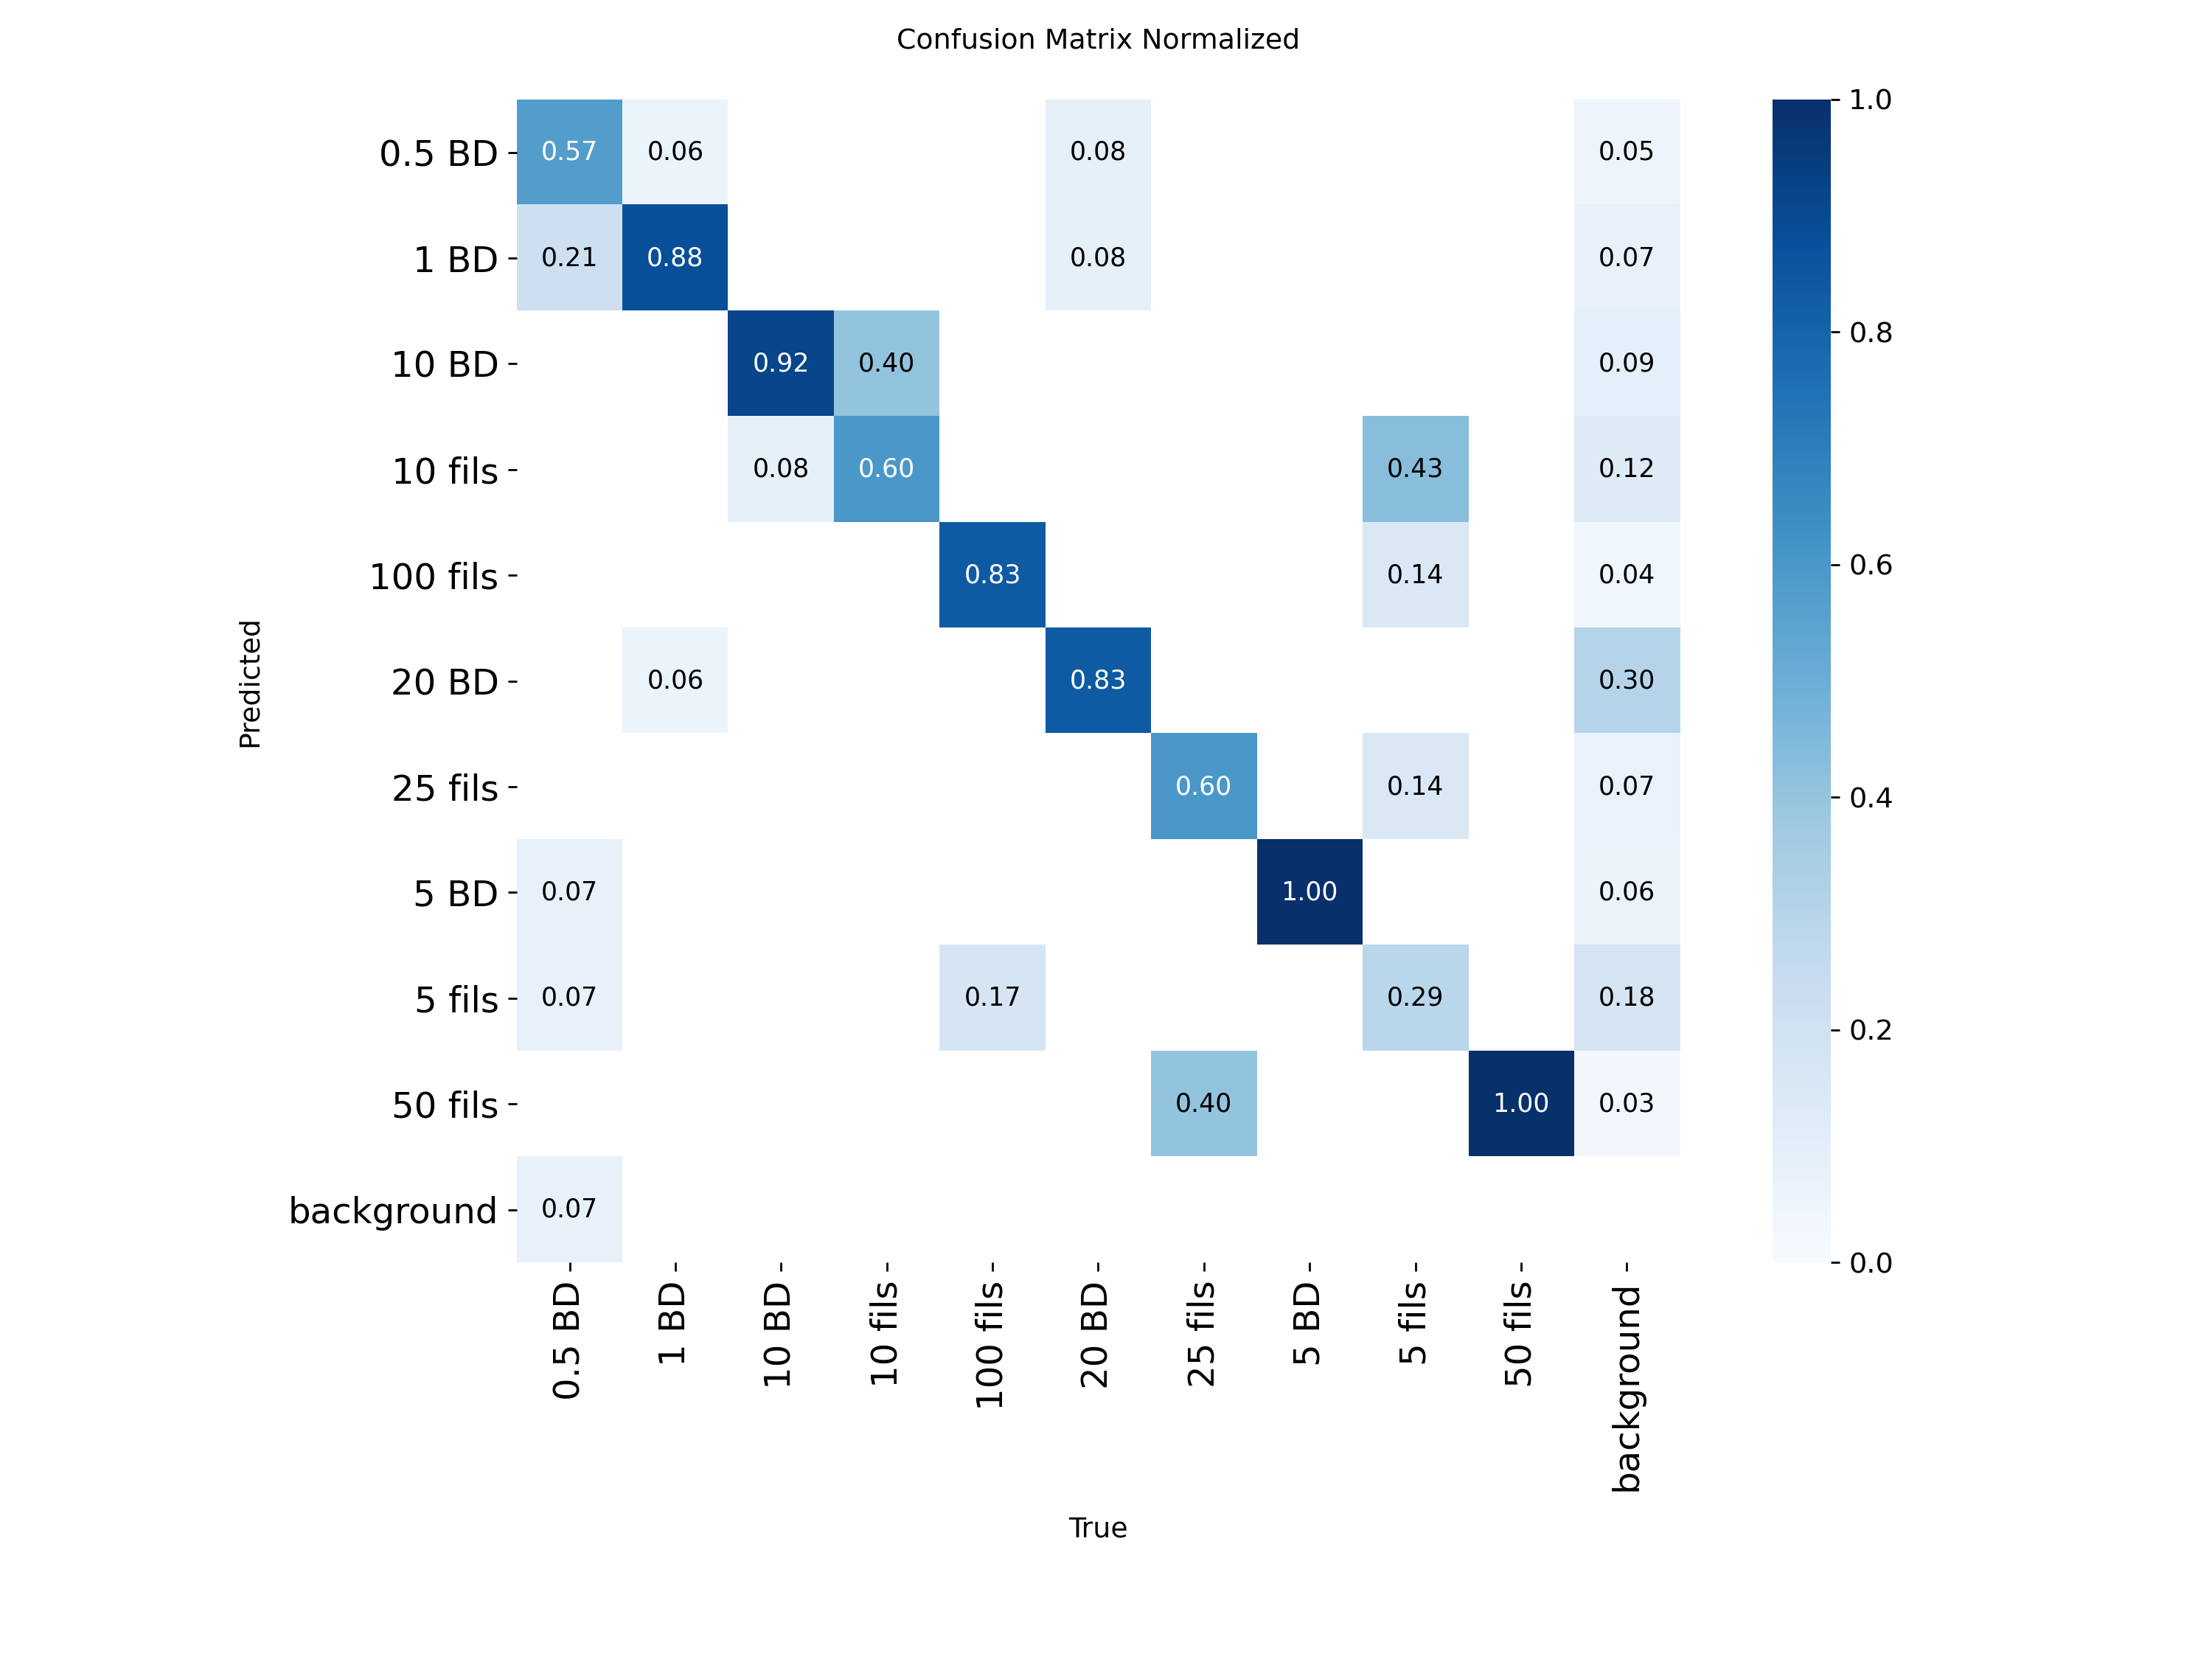

In [17]:
from IPython.display import Image, display

display(Image(filename=str(results.save_dir / "confusion_matrix_normalized.png")))